# Cảnh báo sớm hạ SpO₂ bằng mô hình hybrid (1D-CNN + đặc trưng thống kê)

## Tóm tắt
Từ 60 phút gần nhất của SpO₂ và nhịp mạch (lưới 1 phút), mô hình dự đoán trong 30 phút tiếp theo có xảy ra **đợt SpO₂ < 88% liên tục ≥ 3 phút** hay không. Mô hình đích là bản INT8 chạy trên ESP32 với đầu vào từ cảm biến MAX30102.

## Dữ liệu
- MIMIC-III Waveform Database (matched subset), numerics đưa về lưới 1 phút; chia train/val/test = 70/15/15 **theo bệnh nhân** (799 bệnh nhân có cửa sổ).
- Mẫu: cửa sổ 60 phút × 4 kênh (`spo2_mean`, `spo2_min`, `spo2_valid`, `pulse_mean`). Nhãn dương khi sự kiện bắt đầu trong 30 phút kế tiếp; cửa sổ đã có sự kiện trong 60 phút đầu vào bị loại.
- Lớp dương hiếm (khoảng 1,2%): AUPRC của mô hình ngẫu nhiên bằng tỷ lệ dương (≈ 0,012).

## Phương pháp
| Bước | Kỹ thuật | Lý do |
|---|---|---|
| Biểu diễn chuỗi | z-score theo thống kê train; NaN → 0 kèm 2 kênh mask | mạng nơ-ron không nhận NaN; mask giữ thông tin "thiếu tín hiệu" |
| Đặc trưng thống kê | 20 đặc trưng: mức nền, xu hướng, biến động, gần đây, chất lượng | tín hiệu chính nằm ở mức SpO₂ gần ngưỡng |
| Mô hình | nhánh Conv1D (chuỗi) + nhánh Dense (đặc trưng), gộp, Dense | chuỗi học mẫu hình; đặc trưng mang tín hiệu đã chắt lọc |
| Đầu ra | logit (chưa sigmoid) | lượng tử hóa INT8 làm tròn sigmoid quá thô ở vùng xác suất nhỏ |
| Huấn luyện | BCE, Adam, dừng sớm theo AUPRC val, lưu checkpoint mỗi epoch | tái lập và phục hồi khi gián đoạn |
| Đánh giá | AUPRC, AUROC, recall tại mức báo giả cố định, mô phỏng luồng cảnh báo | accuracy vô nghĩa khi lớp dương hiếm |
| Triển khai | TFLite INT8, kiểm tra suy giảm do lượng tử hóa | chạy trên ESP32 |

## Quy ước đánh giá
- Val dùng để dừng sớm, chọn seed, chọn ngưỡng. **Test chỉ chạy một lần** (mục 5.2).
- Khoảng tin cậy 95% lấy mẫu lại **theo bệnh nhân**; so sánh hai model bằng chênh AUPRC theo cặp.
- 3 seed độc lập; báo cáo trung bình ± độ lệch và ensemble.

## Mục lục
1 Cấu hình · 2 Dữ liệu · 3 Mô hình · 4 Huấn luyện · 5 Đánh giá · 6 Mức cảnh báo · 7 Xuất model · 8 Suy luận thử · 9 Tổng kết

## 1. Cấu hình
Toàn bộ siêu tham số nằm trong `CFG`; các mục sau chỉ đọc từ đây.

| Nhóm | Tham số | Ý nghĩa |
|---|---|---|
| Đường dẫn | `DATA_DIR`, `RUN_ROOT`, `EXPORT_DIR` | dữ liệu cửa sổ; checkpoint từng seed; model xuất |
| Huấn luyện | `SEEDS`, `BATCH`, `MAX_EPOCHS`, `PATIENCE`, `LR` | 3 seed; dừng sớm khi `val_auprc` không tăng sau `PATIENCE` epoch |
| Kiến trúc | `FILTERS`, `KERNEL`, `DROPOUT`, `TAB_UNITS` | nhánh chuỗi và nhánh đặc trưng |
| So sánh | `BASELINES` | điểm dự đoán đã lưu của LightGBM và quy tắc |
| Cảnh báo | `TIERS` | ngân sách báo giả/giờ, persistence `k/n`, cooldown (phút) của tầng Watch và Alert |

**Phục hồi:** mất kết nối hoặc ngắt kernel thì chạy lại notebook từ đầu, mỗi seed tự tiếp tục từ epoch cuối đã lưu. Không đổi `CFG` giữa chừng; thử cấu hình mới thì đổi `RUN_ROOT`; train lại từ đầu thì xóa thư mục `RUN_ROOT`.

In [19]:
import os, json, time, glob, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tqdm.auto import tqdm
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
import eval_utils as E, sim_alert as SA

CFG = dict(
    DATA_DIR="../data/data/dataset_thr88", RUN_ROOT="runs/hybrid_v2", EXPORT_DIR="models_v2",
    SEEDS=(1, 2, 3), BATCH=512, MAX_EPOCHS=40, PATIENCE=6, LR=1e-3,
    FILTERS=(16, 32, 32), KERNEL=5, DROPOUT=0.2, TAB_UNITS=32,
    BASELINES=dict(lgbm="runs/lgbm", quy_tac="runs/rule"),            
    TIERS=dict(watch=dict(fa=0.5, k=1, n=1, cooldown=30), alert=dict(fa=0.2, k=1, n=1, cooldown=60)),
)
ROOT, D = CFG["RUN_ROOT"], CFG["DATA_DIR"]; os.makedirs(ROOT, exist_ok=True)
P = lambda f: f"{ROOT}/{f}"
sig = lambda z: 1 / (1 + np.exp(-z))
CLEAN_DIR = os.path.join(os.path.dirname(D), "clean_1min")
print("TensorFlow", tf.__version__, "| CPU:", os.cpu_count(), "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | CPU: 12 | GPU: []


## 2. Dữ liệu

### 2.1 Nạp cửa sổ
Mỗi file `.npz` gồm `X` (n, 60, 4), `y`, và siêu dữ liệu `pid` (bệnh nhân), `rec` (record), `start` (phút bắt đầu cửa sổ) dùng cho đánh giá theo bệnh nhân và mô phỏng luồng cảnh báo. Kiểm tra: số cửa sổ dương mỗi tập và tỷ lệ dương, vốn là mốc AUPRC của mô hình ngẫu nhiên.

In [20]:
def load(k):
    z = np.load(f"{D}/{k}.npz")
    return z["X"], z["y"].astype("float32"), {c: z[c] for c in ("pid", "rec", "start")}
(Xtr_raw, ytr, _), (Xva_raw, yva, MV), (Xte_raw, yte, MT) = (load(k) for k in ("train", "val", "test"))
yv, yt = yva.astype("int8"), yte.astype("int8")
print(f"train {Xtr_raw.shape} dương {int(ytr.sum())} | val {Xva_raw.shape} dương {int(yva.sum())} | test {Xte_raw.shape} dương {int(yte.sum())}")
print(f"Tỷ lệ dương (mốc AUPRC ngẫu nhiên): train {ytr.mean():.4f} | val {yva.mean():.4f} | test {yte.mean():.4f}")

train (340195, 60, 4) dương 4205 | val (70513, 60, 4) dương 868 | test (71600, 60, 4) dương 917
Tỷ lệ dương (mốc AUPRC ngẫu nhiên): train 0.0124 | val 0.0123 | test 0.0128


### 2.2 Trích xuất đặc trưng thống kê
Từ mỗi cửa sổ 60 phút (đơn vị gốc, bỏ qua NaN) tính 20 đặc trưng, chia 4 nhóm:

| Nhóm | Đặc trưng | Ý nghĩa |
|---|---|---|
| Nền (8) | `sp_mean`, `sp_med`, `sp_p10`, `mn_min60`, `frac_lt95/92/90`, `pu_mean` | mức SpO₂ chung và thời gian ở vùng thấp |
| Động (8) | độ dốc 60 và 30 phút, chênh 10 phút cuối so với 30 phút đầu, độ lệch chuẩn 60 và 15 phút (SpO₂, mạch) | xu hướng và biến động |
| Gần đây (2) | `mn_min10`, `sp_last5` | mức SpO₂ ở những phút cuối |
| Chất lượng (2) | `valid_mean`, `sp_nan_frac` | độ tin cậy của tín hiệu |

Đặc trưng được lưu vào `features_thr88/*.parquet`.

In [21]:
TAB = ["sp_mean", "sp_med", "sp_p10", "mn_min60", "frac_lt95", "frac_lt92", "frac_lt90", "pu_mean",
       "sp_slope60", "sp_slope30", "sp_d_last10_first30", "sp_std60", "sp_std15", "pu_slope30", "pu_d_last10_first30", "pu_std60",
       "mn_min10", "sp_last5", "valid_mean", "sp_nan_frac"]
FEAT_DIR = os.path.join(os.path.dirname(D), "features_thr88")

def slope(Y, lo):                                   # độ dốc hồi quy tuyến tính (đơn vị/phút), bỏ qua NaN
    y = Y[:, lo:]; t = np.arange(y.shape[1], dtype=np.float32); m = ~np.isnan(y)
    n, yy = m.sum(1), np.where(m, y, 0)
    Sx, Sy, Sxy, Sxx = (m * t).sum(1), yy.sum(1), (yy * t).sum(1), (m * t * t).sum(1)
    den = n * Sxx - Sx ** 2
    with np.errstate(all="ignore"): s = (n * Sxy - Sx * Sy) / den
    s[(n < 5) | (den == 0)] = np.nan
    return s
def frac_below(SP, thr):
    v = ~np.isnan(SP); return ((SP < thr) & v).sum(1) / np.maximum(v.sum(1), 1)

def make_features(X):                               # X: (n, 60, 4) chưa chuẩn hóa; kênh = spo2_mean, spo2_min, spo2_valid, pulse_mean
    import warnings
    SP, MN, VA, PU = (X[:, :, i] for i in range(4))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f = {"sp_mean": np.nanmean(SP, 1), "sp_med": np.nanmedian(SP, 1), "sp_p10": np.nanpercentile(SP, 10, axis=1),
             "mn_min60": np.nanmin(MN, 1), "frac_lt95": frac_below(SP, 95), "frac_lt92": frac_below(SP, 92),
             "frac_lt90": frac_below(SP, 90), "pu_mean": np.nanmean(PU, 1),
             "sp_slope60": slope(SP, 0), "sp_slope30": slope(SP, 30),
             "sp_d_last10_first30": np.nanmean(SP[:, 50:], 1) - np.nanmean(SP[:, :30], 1),
             "sp_std60": np.nanstd(SP, 1), "sp_std15": np.nanstd(SP[:, 45:], 1),
             "pu_slope30": slope(PU, 30), "pu_d_last10_first30": np.nanmean(PU[:, 50:], 1) - np.nanmean(PU[:, :30], 1),
             "pu_std60": np.nanstd(PU, 1), "mn_min10": np.nanmin(MN[:, 50:], 1), "sp_last5": np.nanmean(SP[:, 55:], 1),
             "valid_mean": np.nanmean(VA, 1), "sp_nan_frac": np.isnan(SP).mean(1)}
    return pd.DataFrame(f).astype("float32")[TAB]

def get_features(k, X, y):                          # đọc bản đã lưu, nếu chưa có thì tính và lưu
    f = f"{FEAT_DIR}/{k}.parquet"
    if os.path.exists(f): F = pd.read_parquet(f)
    else: os.makedirs(FEAT_DIR, exist_ok=True); F = make_features(X); F["y"] = y.astype("int8"); F.to_parquet(f, index=False)
    assert (F["y"].to_numpy() == y).all(), f"{k}: thứ tự hàng của đặc trưng không khớp dữ liệu"
    return F[TAB]
Ftab = {k: get_features(k, X, y) for k, X, y in (("train", Xtr_raw, ytr), ("val", Xva_raw, yva), ("test", Xte_raw, yte))}
print("Đặc trưng thống kê:", {k: v.shape for k, v in Ftab.items()})

Đặc trưng thống kê: {'train': (340195, 20), 'val': (70513, 20), 'test': (71600, 20)}


### 2.3 Chuẩn hóa và đầu vào cuối
- **Chuỗi:** `(x − mean) / std` theo từng kênh, thống kê **chỉ tính trên train**; NaN → 0 (tức mức trung bình), kèm 2 kênh mask (1 = thiếu) cho `spo2_mean` và `pulse_mean`. Đầu vào cuối `seq`: `(N, 60, 6)`.
- **Đặc trưng:** điền trung vị train, z-score theo train, cắt ±5. Đầu vào `tab`: `(N, 20)`.
- Các thống kê được lưu (`norm.npz`, `tab_norm.npz`) vì **firmware phải chuẩn hóa y hệt**; thiếu một trong hai là nguồn lệch kết quả thường gặp nhất giữa Python và thiết bị.

In [22]:
# --- chuỗi: z-score theo train + NaN -> 0 + 2 kênh mask ---
if os.path.exists(P("norm.npz")): mu, sd = (np.load(P("norm.npz"))[k] for k in ("mu", "sd"))
else:
    mu = np.nanmean(Xtr_raw, (0, 1), dtype=np.float64)       # float64: cộng dồn float32 trên 20 triệu phần tử bị sai số lớn
    sd = np.nanstd(Xtr_raw, (0, 1), dtype=np.float64) + 1e-6
    assert 80 < mu[0] <= 100, f"SpO2 trung bình bất thường: {mu[0]}"
    np.savez(P("norm.npz"), mu=mu, sd=sd)
def prep(X):
    mask = np.isnan(X[:, :, [0, 3]]).astype("float32")
    return np.concatenate([np.nan_to_num((X - mu) / sd, nan=0.0).astype("float32"), mask], axis=2)
Xtr, Xva, Xte = prep(Xtr_raw), prep(Xva_raw), prep(Xte_raw); del Xtr_raw, Xva_raw, Xte_raw

# --- đặc trưng thống kê: điền trung vị, z-score theo train, cắt ±5 ---
if os.path.exists(P("tab_norm.npz")): z_ = np.load(P("tab_norm.npz")); med, tmu, tsd = (pd.Series(z_[k], index=TAB) for k in ("med", "mu", "sd"))
else:
    med = Ftab["train"].median(); _imp = Ftab["train"].fillna(med); tmu, tsd = _imp.mean(), _imp.std() + 1e-6
    np.savez(P("tab_norm.npz"), med=med.to_numpy(), mu=tmu.to_numpy(), sd=tsd.to_numpy(), cols=np.array(TAB))
tab = lambda k: ((Ftab[k].fillna(med) - tmu) / tsd).clip(-5, 5).to_numpy("float32")
XT_tr, XT_va, XT_te = ({"seq": s, "tab": tab(k)} for s, k in ((Xtr, "train"), (Xva, "val"), (Xte, "test")))
assert not np.isnan(Xtr).any() and not np.isnan(XT_tr["tab"]).any()
print("Đầu vào cuối:", {k: v.shape for k, v in XT_tr.items()}, "| SpO2: mean %.2f, sd %.2f" % (mu[0], sd[0]))

Đầu vào cuối: {'seq': (340195, 60, 6), 'tab': (340195, 20)} | SpO2: mean 97.16, sd 2.39


## 3. Mô hình hybrid

```text
seq (60×6) → Conv1D(16,k5) → MaxPool → Conv1D(32,k5) → MaxPool → Conv1D(32,k3) → GlobalAvgPool ─┐
tab (20)   → Dense(32, ReLU) ───────────────────────────────────────────────────────────────────┴→ Concat(64) → Dropout → Dense(16) → Dense(1) = logit
```

- Khoảng 7.900 tham số, đủ nhỏ cho vi điều khiển.
- **Hai nhánh bổ sung nhau:** nhánh Conv1D học mẫu hình theo thời gian từ chuỗi thô; nhánh Dense dùng các đặc trưng thống kê đã chứng minh hiệu quả (mức SpO₂ gần ngưỡng).
- **Đầu ra là logit**, loss `BinaryCrossentropy(from_logits=True)`. Sigmoid áp dụng ở ngoài mô hình, vì lượng tử hóa INT8 làm tròn sigmoid theo bước thô trong khi ngưỡng cảnh báo nằm ở vùng xác suất 0,03-0,06.
- AUPRC/AUROC được tính chính xác bằng scikit-learn sau mỗi epoch (metric AUC của Keras chỉ dùng 200 ngưỡng chia đều, quá thô khi xác suất đa số nhỏ hơn 0,2).

In [23]:
def build_hybrid(lr=CFG["LR"]):
    L = keras.layers
    s = keras.Input((60, 6), name="seq"); t = keras.Input((len(TAB),), name="tab"); x = s
    for i, f in enumerate(CFG["FILTERS"]):
        x = L.Conv1D(f, CFG["KERNEL"] if i < 2 else 3, padding="same", activation="relu")(x)
        if i < 2: x = L.MaxPooling1D(2)(x)
    z = L.Concatenate()([L.GlobalAveragePooling1D()(x), L.Dense(CFG["TAB_UNITS"], activation="relu")(t)])
    z = L.Dense(16, activation="relu")(L.Dropout(CFG["DROPOUT"])(z))
    m = keras.Model([s, t], L.Dense(1)(z), name="hybrid")                       # đầu ra: logit
    m.compile(keras.optimizers.Adam(lr), keras.losses.BinaryCrossentropy(from_logits=True)); return m
build_hybrid().summary()

Model: "hybrid"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ seq (InputLayer)    │ (None, 60, 6)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 60, 16)    │        496 │ seq[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_8     │ (None, 30, 16)    │          0 │ conv1d_12[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 30, 32)    │      2,592 │ max_pooling1d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_9     │ (None, 15, 32)    │          0 │ conv1d_13[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 15, 32)    │      3,104 │ max_pooling1d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tab (InputLayer)    │ (None, 20)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ conv1d_14[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 32)        │        672 │ tab[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 64)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ concatenate_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 16)        │      1,040 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 1)         │         17 │ dense_13[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,921 (30.94 KB)

 Trainable params: 7,921 (30.94 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Huấn luyện có lưu trạng thái

### 4.1 Quy trình
Mỗi seed là một run độc lập (`RUN_ROOT/s<seed>`). Sau **mỗi epoch**, callback `RunManager`:
1. Đo AUPRC/AUROC chính xác trên val và AUPRC trên một tập con train (cùng chế độ đánh giá để so sánh được).
2. Lưu `last.keras` (trọng số + trạng thái optimizer) và `state.json` (epoch, tốt nhất, bộ đếm kiên nhẫn, lịch sử); ghi qua file tạm rồi đổi tên nên không hỏng nếu ngắt giữa lúc ghi.
3. Lưu `best.keras` khi `val_auprc` tăng.
4. In một dòng của bảng, cập nhật thanh tiến độ tổng (đã chạy, ETA tối đa) và thanh tiến độ trong epoch.

### 4.2 Cách đọc bảng
`loss`/`val_loss` là BCE; `auprc` (train, tập con) và `val_auprc` cùng đo bằng scikit-learn; `gap = auprc − val_auprc`.
- `loss` giảm mà `val_loss` tăng nhiều epoch liền: nghi **overfit** (callback gắn cảnh báo).
- `gap` tăng đều: mô hình bắt đầu thuộc lòng train.
- `val_auprc` sát mốc ngẫu nhiên và phẳng: **underfit** hoặc tín hiệu yếu.
- Val chỉ có khoảng 54 bệnh nhân dương, nên `val_auprc` giữa các epoch dao động là bình thường; đánh giá theo **xu hướng**, không theo một epoch.
- ETA là cận trên vì dừng sớm có thể kết thúc sớm hơn.

### 4.3 Chạy (tự resume)
Run đã `done` được bỏ qua. Dừng tay bằng nút Interrupt: epoch đang dở làm lại, epoch đã xong không mất.

In [24]:
take = lambda X, idx: {k: v[idx] for k, v in X.items()}

class RunManager(keras.callbacks.Callback):
    """Sau mỗi epoch: đo AUPRC/AUROC (sklearn, chính xác), lưu last/best/state, in một dòng của bảng, cập nhật thanh tiến độ."""
    def __init__(self, run, st, Xs, ys):
        super().__init__(); self.run, self.st, self.Xs, self.ys = run, st, Xs, ys
    def _save(self, path): tmp = path + ".tmp.keras"; self.model.save(tmp); os.replace(tmp, path)      # ghi file tạm rồi đổi tên
    def _prob(self, X): return sig(self.model.predict(X, batch_size=4096, verbose=0).ravel())
    def on_train_begin(self, logs=None):
        self.outer = tqdm(total=CFG["MAX_EPOCHS"], initial=self.st["epoch"], desc=self.run, unit="epoch", position=0)
        self.outer.write(f"{'Ep':>3} | {'loss':>7} {'val_loss':>8} | {'auprc':>6} {'val_auprc':>9} {'val_auroc':>9} | {'gap':>6} | {'giây':>5} | ghi chú")
    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time(); self.inner = tqdm(total=self.params["steps"], desc=f"Epoch {epoch + 1}", leave=False, position=1)
    def on_train_batch_end(self, batch, logs=None): self.inner.update(1)
    def on_epoch_end(self, epoch, logs=None):
        self.inner.close(); st = self.st; pv, ps = self._prob(XT_va), self._prob(self.Xs)
        r = dict(epoch=epoch + 1, loss=logs["loss"], val_loss=logs["val_loss"], auprc=average_precision_score(self.ys, ps),
                 val_auprc=average_precision_score(yva, pv), val_auroc=roc_auc_score(yva, pv), sec=time.time() - self.t0)
        r["gap"] = r["auprc"] - r["val_auprc"]; H = st["history"]; H.append(r); note = []
        if r["val_auprc"] > st["best"]:
            st["best"], st["best_epoch"], st["wait"] = r["val_auprc"], r["epoch"], 0; self._save(f"{self.run}/best.keras"); note.append("★ tốt nhất")
        else: st["wait"] += 1
        if len(H) >= 3 and H[-1]["val_loss"] > H[-2]["val_loss"] > H[-3]["val_loss"] and H[-1]["loss"] < H[-3]["loss"]:
            note.append("⚠ val_loss tăng 2 epoch liền (nghi overfit)")
        st["epoch"] = r["epoch"]; st["done"] = st["wait"] >= CFG["PATIENCE"] or r["epoch"] >= CFG["MAX_EPOCHS"]
        self._save(f"{self.run}/last.keras")                                                           # CHECKPOINT sau mỗi epoch
        json.dump(st, open(f"{self.run}/state.json.tmp", "w")); os.replace(f"{self.run}/state.json.tmp", f"{self.run}/state.json")
        self.outer.update(1)
        self.outer.write(f"{r['epoch']:>3} | {r['loss']:7.4f} {r['val_loss']:8.4f} | {r['auprc']:6.3f} {r['val_auprc']:9.3f} "
                         f"{r['val_auroc']:9.3f} | {r['gap']:6.3f} | {r['sec']:5.0f} | {' '.join(note)}")
        if st["done"]:
            self.model.stop_training = True
            self.outer.write("■ Dừng: " + ("hết kiên nhẫn (early stopping)" if st["wait"] >= CFG["PATIENCE"] else "đủ số epoch tối đa"))
    def on_train_end(self, logs=None): self.outer.close()

def train_seed(seed):
    run = f"{ROOT}/s{seed}"; os.makedirs(run, exist_ok=True); keras.utils.set_random_seed(seed)
    if os.path.exists(f"{run}/state.json") and os.path.exists(f"{run}/last.keras"):           # RESUME
        st = json.load(open(f"{run}/state.json")); model = keras.models.load_model(f"{run}/last.keras")
        print(f"♻ seed {seed}: tiếp tục từ epoch {st['epoch']} (tốt nhất epoch {st['best_epoch']}, val_auprc {st['best']:.3f})")
    else:
        st = dict(epoch=0, best=-1.0, best_epoch=-1, wait=0, done=False, history=[]); model = build_hybrid()
        json.dump(CFG, open(f"{run}/config.json", "w"), indent=1)
    if st["done"]: print(f"✔ seed {seed}: đã xong (val_auprc {st['best']:.3f} ở epoch {st['best_epoch']})"); return st
    sub = np.random.default_rng(1).choice(len(ytr), min(70000, len(ytr)), replace=False)       # tập con train để đo AUPRC
    model.fit(XT_tr, ytr, validation_data=(XT_va, yva), batch_size=CFG["BATCH"], epochs=CFG["MAX_EPOCHS"], initial_epoch=st["epoch"],
              callbacks=[RunManager(run, st, take(XT_tr, sub), ytr[sub])], verbose=0)
    return st

ST = {s: train_seed(s) for s in CFG["SEEDS"]}

runs/hybrid_v2/s1:   0%|          | 0/40 [00:00<?, ?epoch/s]

 Ep |    loss val_loss |  auprc val_auprc val_auroc |    gap |  giây | ghi chú


Epoch 1:   0%|          | 0/665 [00:00<?, ?it/s]

  1 |  0.0726   0.0600 |  0.096     0.061     0.765 |  0.036 |    13 | ★ tốt nhất


Epoch 2:   0%|          | 0/665 [00:00<?, ?it/s]

...

 13 |  0.0525   0.0606 |  0.184     0.069     0.765 |  0.115 |    10 | ⚠ val_loss tăng 2 epoch liền (nghi overfit)


Epoch 14:   0%|          | 0/665 [00:00<?, ?it/s]

 14 |  0.0520   0.0608 |  0.194     0.070     0.763 |  0.124 |    10 | ⚠ val_loss tăng 2 epoch liền (nghi overfit)


Epoch 15:   0%|          | 0/665 [00:00<?, ?it/s]

 15 |  0.0516   0.0614 |  0.203     0.065     0.757 |  0.138 |    10 | ⚠ val_loss tăng 2 epoch liền (nghi overfit)
■ Dừng: hết kiên nhẫn (early stopping)


### 4.4 Đường cong học
Ba biểu đồ, mỗi seed một màu: loss (nét đứt = train, nét liền = val), AUPRC (cùng quy ước, có mốc ngẫu nhiên) và gap AUPRC. Đường chấm dọc là epoch tốt nhất của từng seed (model dùng ở các mục sau). Ba seed cho đường cong gần nhau thì kết quả ít phụ thuộc khởi tạo ngẫu nhiên.

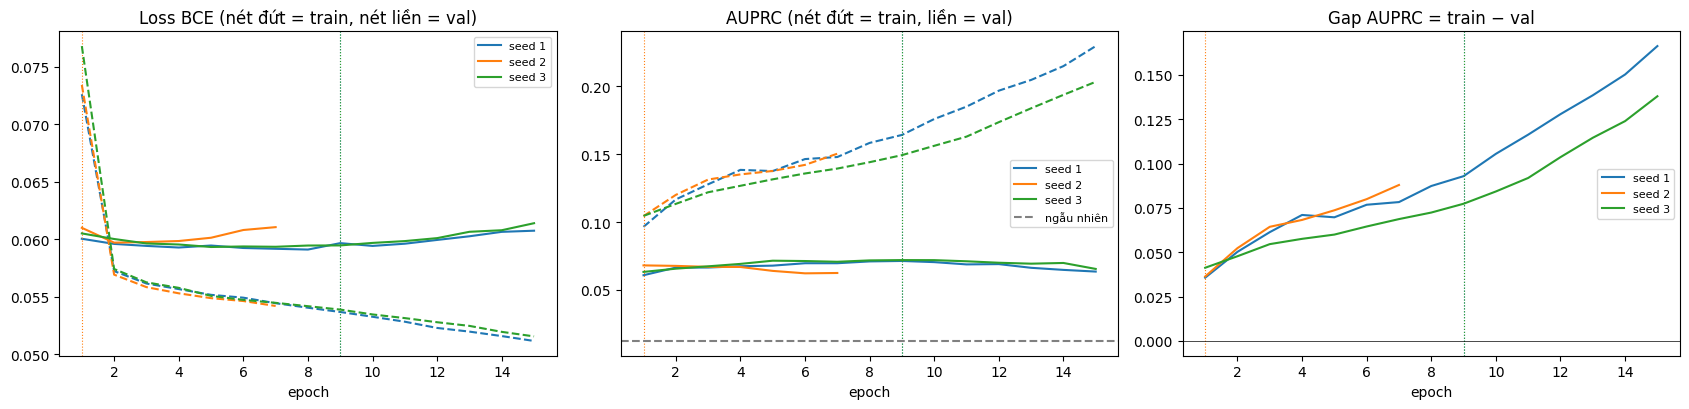

,epoch_tot_nhat,val_auprc,so_epoch_da_chay
seed 1,9.0,0.0713,15.0
seed 2,1.0,0.0680,7.0
seed 3,9.0,0.0719,15.0


In [25]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for i, s in enumerate(CFG["SEEDS"]):
    H = pd.DataFrame(ST[s]["history"]); c = f"C{i}"; b = ST[s]["best_epoch"]
    ax[0].plot(H.epoch, H.loss, c=c, ls="--"); ax[0].plot(H.epoch, H.val_loss, c=c, label=f"seed {s}")
    ax[1].plot(H.epoch, H.auprc, c=c, ls="--"); ax[1].plot(H.epoch, H.val_auprc, c=c, label=f"seed {s}")
    ax[2].plot(H.epoch, H.gap, c=c, label=f"seed {s}")
    for a in ax: a.axvline(b, ls=":", c=c, lw=.8)
ax[1].axhline(yva.mean(), ls="--", c="gray", label="ngẫu nhiên")
ax[0].set(title="Loss BCE (nét đứt = train, nét liền = val)", xlabel="epoch"); ax[1].set(title="AUPRC (nét đứt = train, liền = val)", xlabel="epoch")
ax[2].set(title="Gap AUPRC = train − val", xlabel="epoch"); ax[2].axhline(0, c="k", lw=.5)
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame({f"seed {s}": dict(epoch_tot_nhat=ST[s]["best_epoch"], val_auprc=round(ST[s]["best"], 4), so_epoch_da_chay=ST[s]["epoch"]) for s in CFG["SEEDS"]}).T)

## 5. Đánh giá

### 5.1 Chấm điểm trên val và chọn ngưỡng
- Mỗi seed dùng `best.keras` (epoch tốt nhất theo val). **Ensemble** là trung bình xác suất của các seed.
- Ngưỡng cảnh báo được chọn **trên val** theo ngân sách báo giả (0,04 / 0,5 / 1 / 2 lần mỗi giờ theo dõi) rồi dùng lại nguyên cho test.
- Chỉ số: AUPRC (có khoảng tin cậy 95% theo bệnh nhân), AUROC, precision, recall, specificity, F1, **recall theo đợt sự kiện** (một đợt được tính là bắt được nếu có ít nhất một cửa sổ dương của đợt đó bị cảnh báo), cảnh báo giả/giờ.
- Brier và ECE đo độ tin cậy của xác suất; biểu đồ reliability cho thấy xác suất dự đoán có khớp tần suất thực hay không.
- Mô hình so sánh: `lgbm` (20 đặc trưng, cây tăng cường) và `quy_tac` (SpO₂ nhỏ nhất 10 phút cuối). **Chưa chạm test ở mục này.**

,AUPRC,AUPRC_CI,lift_vs_random,AUROC,prevalence,n_pos,n_patients,Brier,ECE
model,,,,,,,,,
hybrid_ens,0.075,0.042-0.125,6.120,0.775,0.012,868,121,0.012,0.005
lgbm,0.071,0.042-0.114,5.756,0.771,0.012,868,121,0.012,0.004
quy_tac,0.047,0.030-0.075,3.812,0.728,0.012,868,121,NaN,NaN


thr  precision  recall  specificity     f1  accuracy  \
model      FA/giờ                                                            
hybrid_ens 0.04     0.232      0.171   0.055        0.997  0.084     0.985   
           0.50     0.071      0.092   0.339        0.958  0.145     0.951   
           1.00     0.041      0.062   0.445        0.917  0.109     0.911   
           2.00     0.021      0.042   0.589        0.833  0.079     0.830   
lgbm       0.04     0.127      0.169   0.054        0.997  0.082     0.985   
           0.50     0.034      0.086   0.315        0.958  0.135     0.950   
           1.00     0.022      0.060   0.427        0.917  0.105     0.911   
           2.00     0.014      0.041   0.571        0.833  0.076     0.830   
quy_tac    0.04   -74.000      0.101   0.028        0.997  0.043     0.985   
           0.50   -88.000      0.073   0.243        0.962  0.113     0.953   
           1.00   -90.000      0.064   0.380        0.931  0.110     0.924   
           2.00   -92.000      0.044   0.494        0.865  0.080     0.860   

                   event_recall  FA_per_h  FA_per_day  
model      FA/giờ                                      
hybrid_ens 0.04           0.119     0.040       0.959  
           0.50           0.550     0.500      11.996  
           1.00           0.650     1.000      23.997  
           2.00           0.788     2.000      47.998  
lgbm       0.04           0.162     0.040       0.955  
           0.50           0.494     0.500      11.996  
           1.00           0.656     1.000      23.997  
           2.00           0.788     2.000      47.998  
quy_tac    0.04           0.075     0.037       0.881  
           0.50           0.506     0.459      11.012  
           1.00           0.631     0.829      19.891  
           2.00           0.731     1.624      38.967

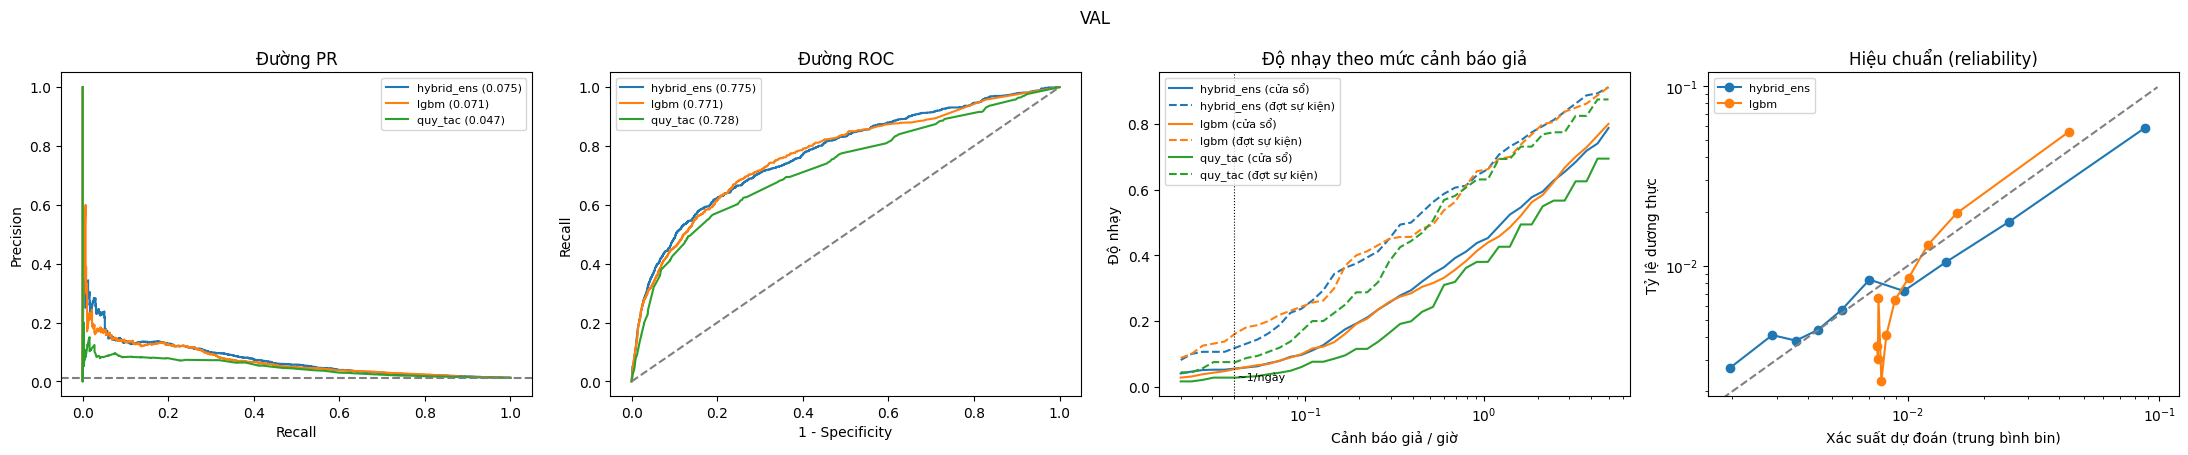

Từng seed (val):


,AUPRC,AUROC
hybrid_s1,0.071,0.768
hybrid_s2,0.068,0.758
hybrid_s3,0.072,0.772


In [26]:
def seed_prob(seed, X): return sig(keras.models.load_model(f"{ROOT}/s{seed}/best.keras").predict(X, batch_size=4096, verbose=0).ravel())
S_val = {f"hybrid_s{s}": seed_prob(s, XT_va) for s in CFG["SEEDS"]}
S_val["hybrid_ens"] = np.mean([S_val[f"hybrid_s{s}"] for s in CFG["SEEDS"]], 0)          # ensemble: trung bình xác suất
for n, p in CFG["BASELINES"].items():
    if os.path.exists(f"{p}_val.npy"): S_val[n] = np.load(f"{p}_val.npy")
MODELS = [n for n in ("hybrid_ens", "lgbm", "quy_tac") if n in S_val]; isp = lambda n: n != "quy_tac"
thr = {n: E.pick_thresholds(S_val[n], yv) for n in S_val}                                   # ngưỡng chọn trên VAL
cv = [E.evaluate(n, S_val[n], yv, thr[n], MV, is_prob=isp(n)) for n in MODELS]
t1, t2 = E.report(cv); display(t1.round(3)); display(t2.round(3)); E.plot_curves(cv, "VAL")
sv = pd.DataFrame({n: dict(AUPRC=average_precision_score(yv, S_val[n]), AUROC=roc_auc_score(yv, S_val[n])) for n in S_val if n.startswith("hybrid_s")}).T
print("Từng seed (val):"); display(sv.round(3))

### 5.2 Đánh giá cuối trên test (chạy một lần)
Chỉ chạy khi đã chốt cấu hình, ngưỡng và seed dựa trên val; đổi bất cứ điều gì sau khi xem test thì kết quả không còn khách quan.

**So sánh có kiểm định:** chênh AUPRC (hybrid − mô hình kia) lấy mẫu lại theo bệnh nhân, 200 lần, báo khoảng tin cậy 95%. Khoảng không chứa 0 thì khác biệt có ý nghĩa; chứa 0 thì chưa phân biệt được. Dùng phép so sánh cặp vì hai mô hình được đánh giá trên cùng tập bệnh nhân, chặt hơn so với đối chiếu hai khoảng tin cậy riêng.

,AUPRC,AUPRC_CI,lift_vs_random,AUROC,prevalence,n_pos,n_patients,Brier,ECE,Brier_isotonic,ECE_isotonic
model,,,,,,,,,,,
hybrid_ens,0.080,0.051-0.111,6.221,0.815,0.013,917,119,0.012,0.003,0.012,0.002
lgbm,0.084,0.049-0.114,6.533,0.812,0.013,917,119,0.012,0.006,0.012,0.003
quy_tac,0.050,0.035-0.066,3.928,0.775,0.013,917,119,NaN,NaN,NaN,NaN


thr  precision  recall  specificity     f1  accuracy  \
model      FA/giờ                                                            
hybrid_ens 0.04     0.232      0.156   0.041        0.997  0.065     0.985   
           0.50     0.071      0.093   0.338        0.957  0.146     0.949   
           1.00     0.041      0.073   0.497        0.918  0.127     0.913   
           2.00     0.021      0.050   0.664        0.837  0.093     0.834   
lgbm       0.04     0.127      0.177   0.058        0.997  0.087     0.984   
           0.50     0.034      0.094   0.368        0.954  0.149     0.946   
           1.00     0.022      0.069   0.487        0.914  0.120     0.909   
           2.00     0.014      0.048   0.666        0.830  0.090     0.828   
quy_tac    0.04   -74.000      0.064   0.015        0.997  0.025     0.985   
           0.50   -88.000      0.074   0.274        0.956  0.117     0.947   
           1.00   -90.000      0.066   0.441        0.919  0.115     0.913   
           2.00   -92.000      0.047   0.601        0.843  0.088     0.840   

                   event_recall  FA_per_h  FA_per_day  
model      FA/giờ                                      
hybrid_ens 0.04           0.125     0.035       0.839  
           0.50           0.607     0.514      12.338  
           1.00           0.750     0.982      23.579  
           2.00           0.863     1.962      47.081  
lgbm       0.04           0.167     0.042       1.006  
           0.50           0.649     0.553      13.275  
           1.00           0.750     1.029      24.708  
           2.00           0.851     2.038      48.907  
quy_tac    0.04           0.048     0.035       0.835  
           0.50           0.589     0.531      12.753  
           1.00           0.720     0.968      23.237  
           2.00           0.815     1.885      45.240

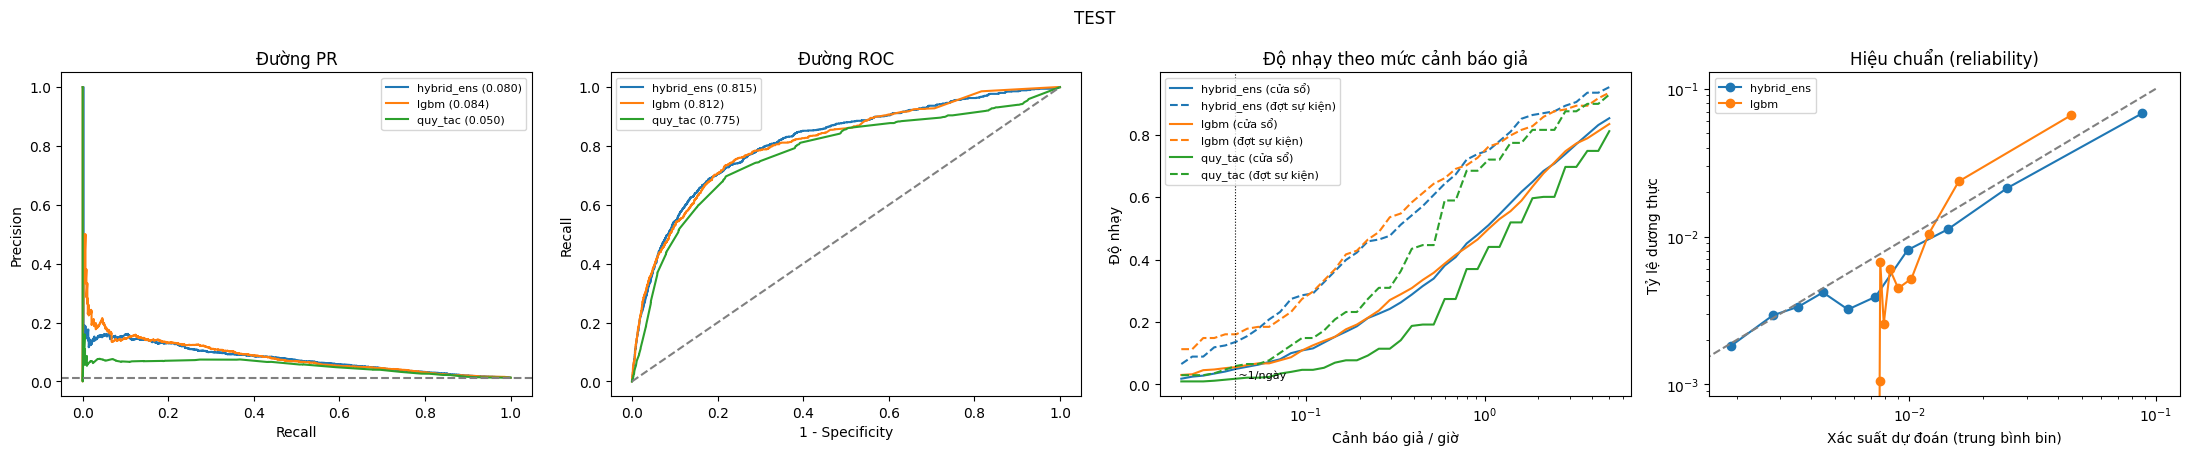

Chênh AUPRC (hybrid_ens − lgbm): 95% CI = [-0.018, 0.010] → chưa phân biệt được
Chênh AUPRC (hybrid_ens − quy_tac): 95% CI = [0.011, 0.056] → khác biệt có ý nghĩa


In [27]:
# CHẠY MỘT LẦN, sau khi đã chốt cấu hình và ngưỡng trên val
S_test = {f"hybrid_s{s}": seed_prob(s, XT_te) for s in CFG["SEEDS"]}
S_test["hybrid_ens"] = np.mean([S_test[f"hybrid_s{s}"] for s in CFG["SEEDS"]], 0)
for n, p in CFG["BASELINES"].items():
    if os.path.exists(f"{p}_test.npy"): S_test[n] = np.load(f"{p}_test.npy")
ct = [E.evaluate(n, S_test[n], yt, thr[n], MT, s_val=S_val[n], y_val=yv, is_prob=isp(n)) for n in MODELS]
t1, t2 = E.report(ct); display(t1.round(3)); display(t2.round(3)); E.plot_curves(ct, "TEST")

def paired_diff(s1, s2, y, pid, n=200, seed=0):          # chênh AUPRC, lấy mẫu lại theo bệnh nhân (cặp)
    codes, uniq = pd.factorize(pid); by = [np.where(codes == i)[0] for i in range(len(uniq))]
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        ii = np.concatenate([by[i] for i in rng.integers(0, len(uniq), len(uniq))])
        if y[ii].sum(): d.append(average_precision_score(y[ii], s1[ii]) - average_precision_score(y[ii], s2[ii]))
    return np.percentile(d, [2.5, 97.5])
PD = {n: paired_diff(S_test["hybrid_ens"], S_test[n], yt, MT["pid"]) for n in MODELS if n != "hybrid_ens"}
for n, ci in PD.items(): print(f"Chênh AUPRC (hybrid_ens − {n}): 95% CI = [{ci[0]:.3f}, {ci[1]:.3f}]", "→ khác biệt có ý nghĩa" if ci[0] > 0 or ci[1] < 0 else "→ chưa phân biệt được")

### 5.3 Precision, recall, F1 và accuracy
Biểu đồ trái: precision, recall (mức cửa sổ), recall mức đợt sự kiện và F1 theo mức cảnh báo giả/giờ **thực đo trên test** (ngưỡng chọn trên val). Biểu đồ phải: accuracy của mô hình so với accuracy của bộ đoán toàn âm. Với lớp dương ≈ 1,2%, bộ đoán toàn âm đã đạt ≈ 98,8%, và accuracy của mô hình giảm khi hạ ngưỡng để bắt nhiều sự kiện hơn. Vì vậy **accuracy không dùng để đánh giá bài toán này**; chỉ số chính là AUPRC và recall tại mức báo giả cố định. Bảng dưới liệt kê các chỉ số tại từng mức.

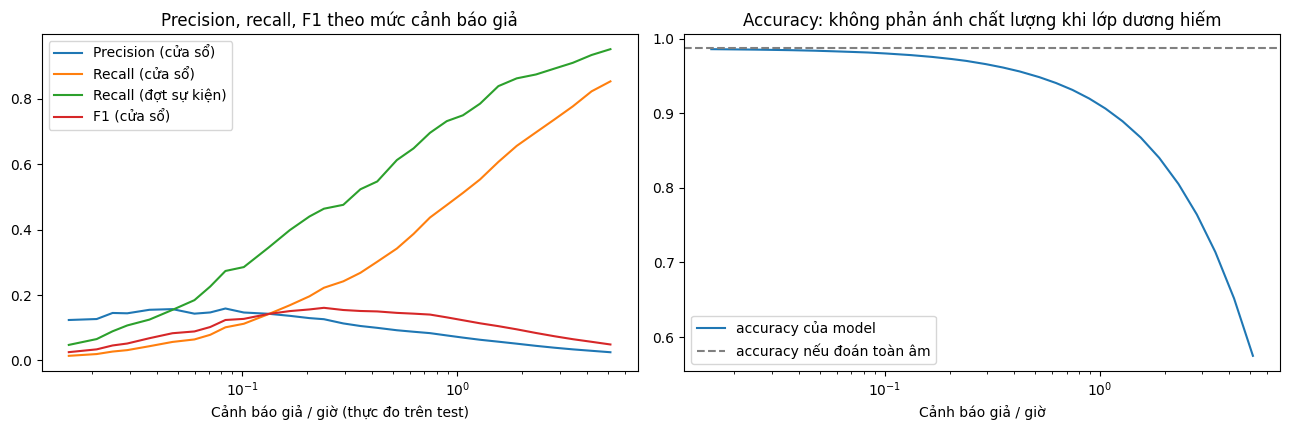

,precision,recall,specificity,f1,accuracy,event_recall,FA_per_h,FA_per_day
FA/giờ,,,,,,,,
0.04,0.156,0.041,0.997,0.065,0.985,0.125,0.035,0.839
0.50,0.093,0.338,0.957,0.146,0.949,0.607,0.514,12.338
1.00,0.073,0.497,0.918,0.127,0.913,0.750,0.982,23.579
2.00,0.050,0.664,0.837,0.093,0.834,0.863,1.962,47.081


In [28]:
c_h = ct[MODELS.index("hybrid_ens")]; fas = np.geomspace(0.02, 5, 30)
OP = pd.DataFrame([{**E._op(c_h["s"], c_h["y"], E.thr_for_fa(S_val["hybrid_ens"], yv, fa), c_h["ep"], c_h["hrs"]), "fa": fa} for fa in fas])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for col, lab in (("precision", "Precision (cửa sổ)"), ("recall", "Recall (cửa sổ)"), ("event_recall", "Recall (đợt sự kiện)"), ("f1", "F1 (cửa sổ)")):
    ax[0].plot(OP["FA_per_h"], OP[col], label=lab)
ax[0].set(xscale="log", xlabel="Cảnh báo giả / giờ (thực đo trên test)", title="Precision, recall, F1 theo mức cảnh báo giả"); ax[0].legend()
ax[1].plot(OP["FA_per_h"], OP["accuracy"], label="accuracy của model"); ax[1].axhline(1 - yt.mean(), ls="--", c="gray", label="accuracy nếu đoán toàn âm")
ax[1].set(xscale="log", xlabel="Cảnh báo giả / giờ", title="Accuracy: không phản ánh chất lượng khi lớp dương hiếm"); ax[1].legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(c_h["ops"]).T.loc[:, ["precision", "recall", "specificity", "f1", "accuracy", "event_recall", "FA_per_h", "FA_per_day"]].round(3).rename_axis("FA/giờ"))

### 5.4 Ma trận nhầm lẫn
Ma trận chuẩn hóa theo hàng (hàng "thực dương" cho recall, hàng "thực âm" cho specificity), ghi cả số đếm, tại bốn mức báo giả: 0,04 / 0,5 / 1 / 2 lần mỗi giờ. Hàng trên là hybrid, hàng dưới là LightGBM. Cảnh báo giả/giờ ở đây tính theo từng cửa sổ (cách nhau 5 phút), nên là **cận trên** của tần suất thực tế khi các cảnh báo liên tiếp được gộp lại (mục 6).

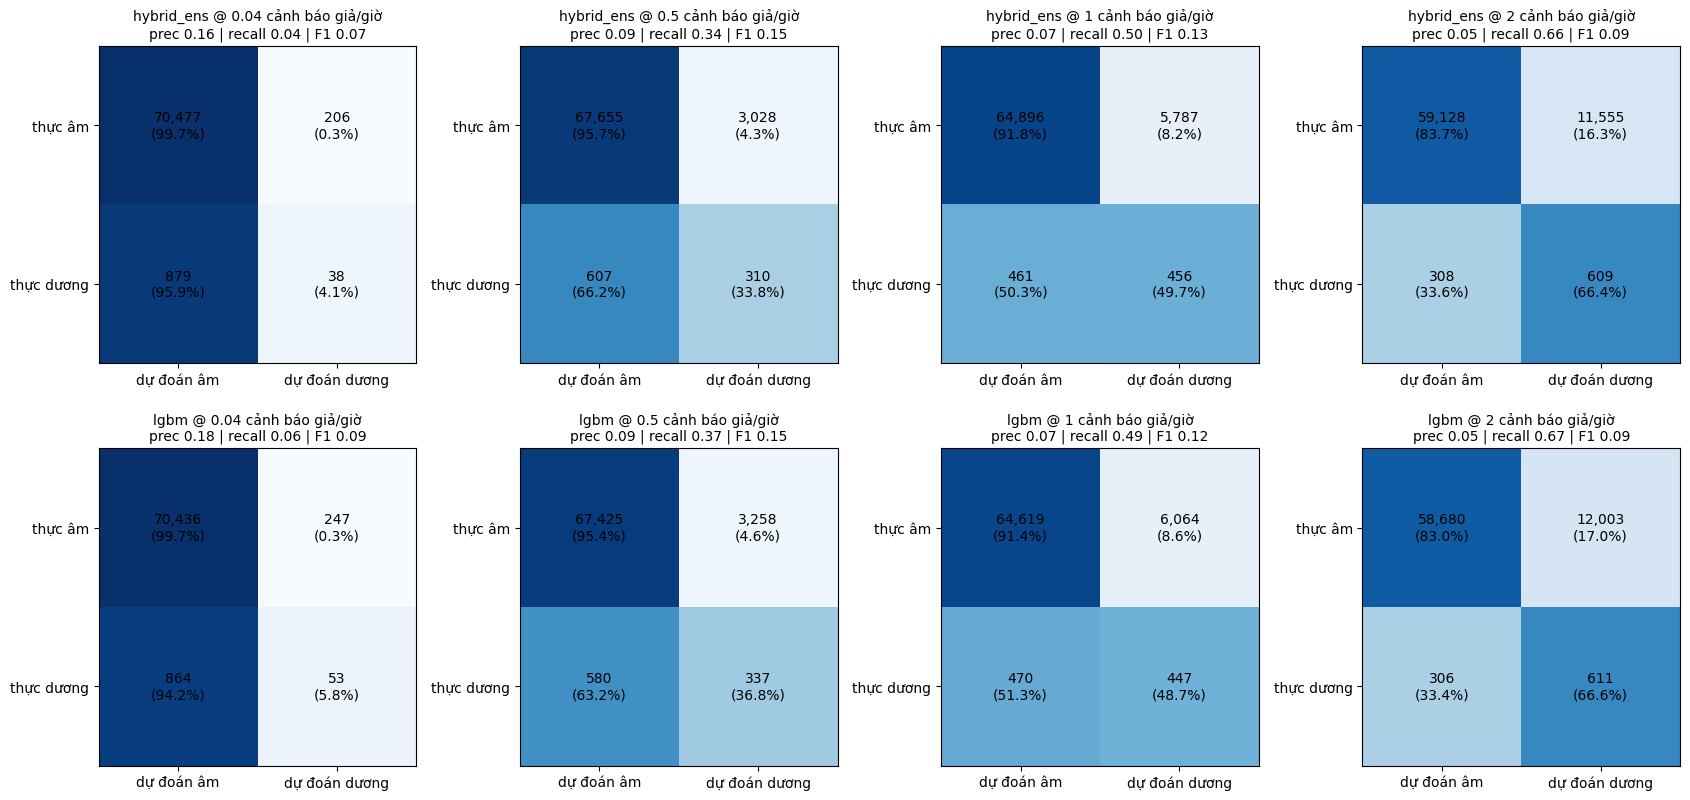

In [29]:
rows = [n for n in ("hybrid_ens", "lgbm") if n in MODELS]; levels = (0.04, 0.5, 1, 2)
fig, ax = plt.subplots(len(rows), 4, figsize=(17, 4.1 * len(rows)), squeeze=False)
for r, n in enumerate(rows):
    c = ct[MODELS.index(n)]
    for a, fa in zip(ax[r], levels):
        o = c["ops"][fa]; cm = np.array([[o["tn"], o["fp"]], [o["fn"], o["tp"]]]); a.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2): a.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center")
        a.set_xticks([0, 1]); a.set_xticklabels(["dự đoán âm", "dự đoán dương"]); a.set_yticks([0, 1]); a.set_yticklabels(["thực âm", "thực dương"])
        a.set_title(f"{n} @ {fa} cảnh báo giả/giờ\nprec {o['precision']:.2f} | recall {o['recall']:.2f} | F1 {o['f1']:.2f}", fontsize=10)
plt.tight_layout(); plt.show()

## 6. Mức cảnh báo

### 6.1 Thiết kế ba tầng
| Tầng | Cơ chế | Cấu hình |
|---|---|---|
| **Critical** | luật: SpO₂ < 88% liên tục ≥ 3 phút (không dùng mô hình) | phát khi đủ 3 phút; gộp các sự kiện cách nhau < 30 phút |
| **Alert** | điểm mô hình ≥ ngưỡng ứng với 0,2 báo giả/giờ | persistence k=1/n=1, cooldown 60 phút |
| **Watch** | điểm mô hình ≥ ngưỡng ứng với 0,5 báo giả/giờ | persistence k=1/n=1, cooldown 30 phút |

Mô hình cho điểm rủi ro mỗi 5 phút; lớp quyết định đặt lên trên gồm ngưỡng, **persistence** (cần k lần vượt trong n lần đánh giá gần nhất) và **cooldown** (khoảng nghỉ giữa hai cảnh báo). Ngưỡng chọn trên val, cấu hình áp lên test.

### 6.2 Chỉ số
- `alerts_per_day`, `FA_per_day`: số cảnh báo và cảnh báo giả mỗi ngày theo dõi (giờ có dữ liệu hợp lệ quy đổi ra 24 giờ).
- `precision`: tỷ lệ cảnh báo có sự kiện bắt đầu trong 30 phút sau đó.
- `caught_any`, `caught_useful`: tỷ lệ sự kiện **đánh giá được** có cảnh báo trước đó; `useful` yêu cầu báo trước ≥ 5 phút.
- `lead_med`: thời gian báo trước trung vị (phút).
- `FA_day_pt_p90`: báo giả/ngày của bệnh nhân ở phân vị 90, thể hiện mức chênh giữa các bệnh nhân.

**Lưu ý đọc kết quả:** (1) "sự kiện đánh giá được" chỉ gồm sự kiện có cửa sổ hợp lệ trong 30 phút trước đó, nên tầng dự đoán không bao phủ các sự kiện nằm ngay sau một sự kiện khác (khi đó đầu vào đã chứa sự kiện); phần này do tầng Critical đảm nhiệm. (2) Timeline không có các cửa sổ ngay sau sự kiện, nên số báo giả/ngày có thể **lạc quan hơn** so với dùng liên tục.

Cấu hình: {'watch': {'fa': 0.5, 'k': 1, 'n': 1, 'cooldown': 30}, 'alert': {'fa': 0.2, 'k': 1, 'n': 1, 'cooldown': 60}} 
TEST, ngưỡng chọn trên val:


alerts_per_day  FA_per_day  precision  caught_any  \
tầng  model                                                           
watch hybrid_ens           4.030       3.648      0.095       0.532   
      lgbm                 4.328       3.922      0.094       0.555   
      quy_tac              4.771       4.417      0.074       0.514   
alert hybrid_ens           1.516       1.283      0.154       0.330   
      lgbm                 1.689       1.452      0.140       0.335   
      quy_tac              1.758       1.605      0.087       0.229   

                  caught_useful  lead_med  FA_day_pt_p90  evaluable  
tầng  model                                                          
watch hybrid_ens          0.408      12.5          9.384      218.0  
      lgbm                0.440      15.0         10.563      218.0  
      quy_tac             0.404      11.0         12.435      218.0  
alert hybrid_ens          0.257      11.0          3.706      218.0  
      lgbm                0.243      11.0          3.147      218.0  
      quy_tac             0.183      11.5          4.787      218.0

Tầng Critical (luật SpO2 < 88% liên tục ≥ 3 phút, không dùng model): {'alerts_per_day': 0.94, 'FA_day_pt_med': 0.19, 'FA_day_pt_p90': 2.92, 'FA_day_pt_max': 8.11, 'n_events': 262.0, 'patients': 111.0}


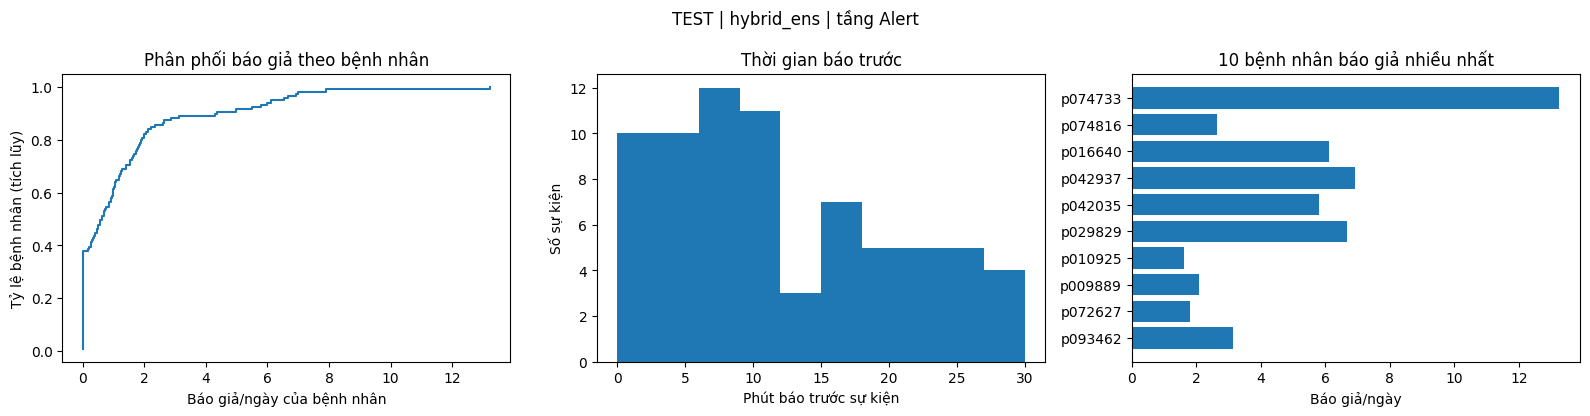

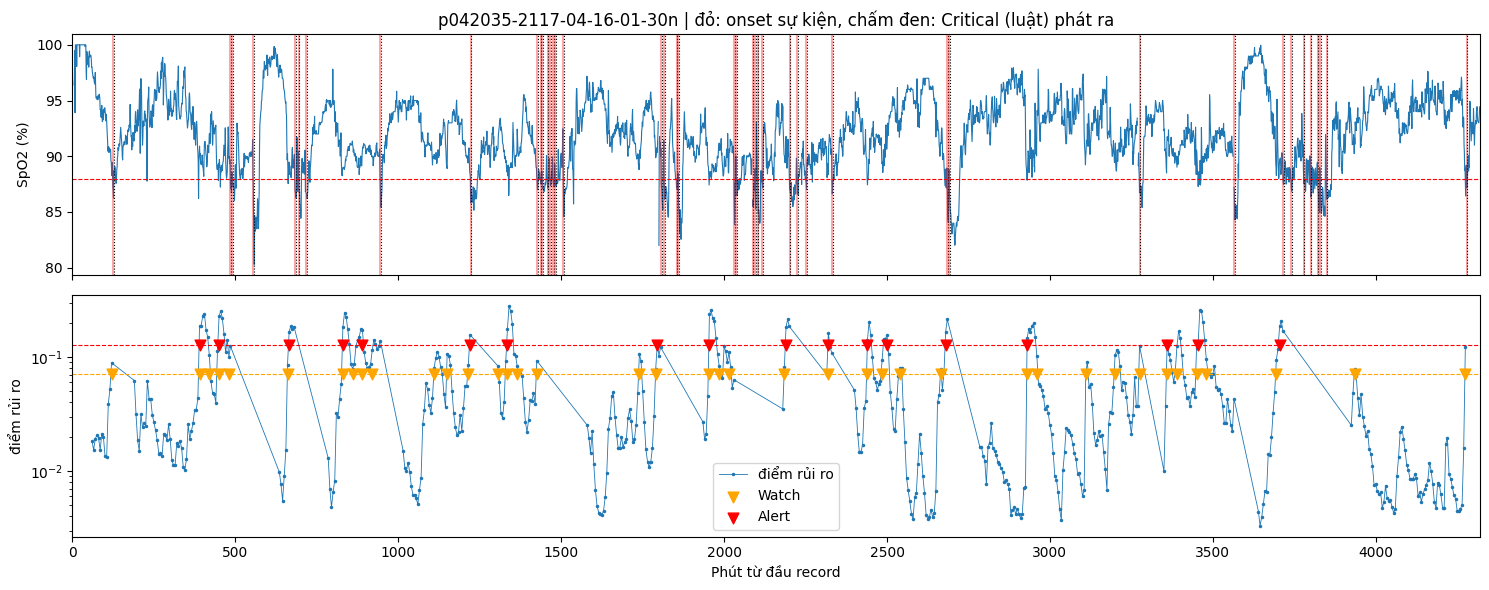

In [30]:
tl_t = {n: SA.build_timelines(S_test[n], MT, CLEAN_DIR) for n in MODELS}
THR_T = {n: {t: E.pick_thresholds(S_val[n], yv, fa_levels=(c["fa"],))[c["fa"]] for t, c in CFG["TIERS"].items()} for n in MODELS}   # ngưỡng chọn trên val
COLS = ["alerts_per_day", "FA_per_day", "precision", "caught_any", "caught_useful", "lead_med", "FA_day_pt_p90", "evaluable"]
TIER_RES = {(t, n): SA.run_stream(tl_t[n], THR_T[n][t], c["k"], c["n"], c["cooldown"]) for t, c in CFG["TIERS"].items() for n in MODELS}
print("Cấu hình:", CFG["TIERS"], "\nTEST, ngưỡng chọn trên val:")
display(pd.DataFrame({k: pd.Series(v[0]) for k, v in TIER_RES.items()}).T[COLS].round(3).rename_axis(["tầng", "model"]))
CRIT = SA.critical_stats(tl_t["hybrid_ens"])
print("Tầng Critical (luật SpO2 < 88% liên tục ≥ 3 phút, không dùng model):", {k: round(float(v), 2) for k, v in CRIT.items()})

summ, pt_, leads_ = TIER_RES[("alert", "hybrid_ens")]; SA.plot_config(pt_, leads_, "TEST | hybrid_ens | tầng Alert")
t0 = tl_t["hybrid_ens"]; rec0 = max(t0, key=lambda r: len(t0[r]["onsets"]) if len(t0[r]["t"]) > 50 else -1)      # record nhiều sự kiện nhất
w, a_ = CFG["TIERS"]["watch"], CFG["TIERS"]["alert"]
SA.plot_example(t0, THR_T["hybrid_ens"]["watch"], THR_T["hybrid_ens"]["alert"], cfg_watch=(w["k"], w["n"], w["cooldown"]),
                cfg_alert=(a_["k"], a_["n"], a_["cooldown"]), rec=rec0)

## 7. Xuất model cho ESP32

### 7.1 Sản phẩm
| File | Nội dung |
|---|---|
| `hybrid_thr88.keras` | model Keras đầy đủ (seed triển khai) |
| `hybrid_thr88_int8.tflite` | bản INT8 cho TFLite Micro; đầu ra là logit đã lượng tử hóa |
| `hybrid_thr88_norm.npz` | thống kê chuẩn hóa chuỗi (`seq_mu`, `seq_sd`) và đặc trưng (`tab_med`, `tab_mu`, `tab_sd`, `tab_cols`) |
| `hybrid_thr88_meta.json` | seed, thứ tự đầu vào, thang lượng tử hóa, ngưỡng cảnh báo (xác suất và logit), cấu hình tầng |

### 7.2 Quyết định kỹ thuật
- **Một seed** (chọn theo val) thay vì ensemble: ensemble chỉ cải thiện nhỏ nhưng nhân số mạng cần chạy trên thiết bị.
- **Dữ liệu đại diện** cho lượng tử hóa: 800 mẫu ngẫu nhiên và 200 mẫu dương, truyền dạng **dict theo tên đầu vào**. Converter sắp xếp đầu vào theo tên (tensor `tab` đứng trước `seq`), nên truyền list `[seq, tab]` làm hỏng hiệu chuẩn; firmware cũng phải đưa dữ liệu đúng thứ tự trong `input_order`.
- **Firmware tiền xử lý y hệt Python:** chuỗi `(x − seq_mu)/seq_sd`, NaN → 0, thêm 2 kênh mask; đặc trưng điền `tab_med`, `(x − tab_mu)/tab_sd`, cắt ±5; sau đó lượng tử hóa theo `scale` và `zero_point` của từng đầu vào.
- **Ngưỡng chọn trên điểm INT8 của val**, vì đó là điểm thiết bị thực sự tính. Bước lượng tử hóa của logit đầu ra được in ra để biết độ phân giải ngưỡng.

### 7.3 Kiểm tra suy giảm do lượng tử hóa
So AUPRC và AUROC của bản float và bản INT8 trên val. Giảm vượt mức chấp nhận (đề xuất 5% tương đối, do người làm đặt) thì xem lại dữ liệu đại diện hoặc kiến trúc. Bộ nhớ tensor tạm (tensor arena) và thời gian suy luận trên ESP32 cần đo trực tiếp trên thiết bị; notebook này chỉ cho kích thước file và số tham số.

In [31]:
EXP = CFG["EXPORT_DIR"]; os.makedirs(EXP, exist_ok=True)
DEPLOY = max(CFG["SEEDS"], key=lambda s: ST[s]["best"])                    
best = keras.models.load_model(f"{ROOT}/s{DEPLOY}/best.keras"); best.save(f"{EXP}/hybrid_thr88.keras")
np.savez(f"{EXP}/hybrid_thr88_norm.npz", seq_mu=mu, seq_sd=sd, tab_cols=np.array(TAB), tab_med=med.to_numpy(), tab_mu=tmu.to_numpy(), tab_sd=tsd.to_numpy())

rng = np.random.default_rng(0)
rep = np.r_[rng.choice(len(ytr), 800, replace=False), np.where(ytr == 1)[0][:200]]       
conv = tf.lite.TFLiteConverter.from_keras_model(best)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = lambda: ({"seq": XT_tr["seq"][i:i + 1], "tab": XT_tr["tab"][i:i + 1]} for i in rep) 
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = conv.inference_output_type = tf.int8
TFL = f"{EXP}/hybrid_thr88_int8.tflite"; open(TFL, "wb").write(conv.convert())

it = tf.lite.Interpreter(model_path=TFL); it.allocate_tensors()
det = it.get_input_details(); d_seq = next(d for d in det if len(d["shape"]) == 3); d_tab = next(d for d in det if len(d["shape"]) == 2)
o = it.get_output_details()[0]; (osc, ozp) = o["quantization"]
q = lambda x, d: np.clip(np.round(x / d["quantization"][0] + d["quantization"][1]), -128, 127).astype(np.int8)
def tflite_logit(Xs, Xt):
    out = np.empty(len(Xs), np.float32)
    for i in tqdm(range(len(Xs)), desc="TFLite INT8", leave=False):
        it.set_tensor(d_seq["index"], q(Xs[i], d_seq)[None]); it.set_tensor(d_tab["index"], q(Xt[i], d_tab)[None]); it.invoke()
        out[i] = (it.get_tensor(o["index"])[0, 0].astype(np.float32) - ozp) * osc
    return out
p8_val = sig(tflite_logit(XT_va["seq"], XT_va["tab"]))
f_val = S_val[f"hybrid_s{DEPLOY}"]
print(f"Seed triển khai: {DEPLOY} | TFLite INT8: {os.path.getsize(TFL) / 1024:.1f} KB | tham số: {best.count_params():,}")
print(f"AUPRC val | float {average_precision_score(yva, f_val):.4f} | INT8 {average_precision_score(yva, p8_val):.4f}"
      f" | AUROC float {roc_auc_score(yva, f_val):.4f} | INT8 {roc_auc_score(yva, p8_val):.4f}")
print(f"Bước lượng tử hóa của đầu ra (logit): {osc:.4f}  → ngưỡng trên thiết bị chỉ phân giải được cỡ này")

# ngưỡng cho firmware: chọn trên điểm INT8 của val, lưu cả thang xác suất và thang logit
THR_DEV = {t: float(E.pick_thresholds(p8_val, yv, fa_levels=(c["fa"],))[c["fa"]]) for t, c in CFG["TIERS"].items()}
meta = dict(deploy_seed=int(DEPLOY), input_order=[d["name"] for d in det], tiers=CFG["TIERS"], thresholds_prob=THR_DEV,
            thresholds_logit={t: float(np.log(p / (1 - p))) for t, p in THR_DEV.items()}, tflite_kb=round(os.path.getsize(TFL) / 1024, 1),
            input_seq=dict(shape=[60, 6], scale=float(d_seq["quantization"][0]), zero_point=int(d_seq["quantization"][1])),
            input_tab=dict(shape=[len(TAB)], scale=float(d_tab["quantization"][0]), zero_point=int(d_tab["quantization"][1])),
            output=dict(scale=float(osc), zero_point=int(ozp), kind="logit"))
json.dump(meta, open(f"{EXP}/hybrid_thr88_meta.json", "w"), indent=1); print("Ngưỡng cho firmware:", meta["thresholds_prob"])

INFO:tensorflow:Assets written to: C:\Users\LENOVO\AppData\Local\Temp\tmplvhihlaf\assets


INFO:tensorflow:Assets written to: C:\Users\LENOVO\AppData\Local\Temp\tmplvhihlaf\assets


Saved artifact at 'C:\Users\LENOVO\AppData\Local\Temp\tmplvhihlaf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 60, 6), dtype=tf.float32, name='seq'), TensorSpec(shape=(None, 20), dtype=tf.float32, name='tab')]
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1858875759200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1858875754624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1858876293712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1858876300576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1858876303040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1858876306032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1858876303568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1858875643280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1858875641696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1859010851968: Tensor

d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\.venv\lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\.venv\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite INT8:   0%|          | 0/70513 [00:00<?, ?it/s]

Seed triển khai: 3 | TFLite INT8: 19.5 KB | tham số: 7,921
AUPRC val | float 0.0719 | INT8 0.0717 | AUROC float 0.7720 | INT8 0.7741
Bước lượng tử hóa của đầu ra (logit): 0.0297  → ngưỡng trên thiết bị chỉ phân giải được cỡ này
Ngưỡng cho firmware: {'watch': 0.059471648186445236, 'alert': 0.12035571038722992}


## 8. Suy luận thử bằng bản INT8

Mục này chạy đúng bản `.tflite` (thứ sẽ nạp lên ESP32) trên toàn bộ test, sau khi ngưỡng đã chốt từ val.

### 8.1 Kết quả theo lớp
Tại ngưỡng của từng tầng: lớp **âm** (specificity: tỷ lệ cửa sổ âm không bị cảnh báo), lớp **dương** (recall: tỷ lệ cửa sổ dương bị bắt), precision và accuracy.

### 8.2 Độ tin cậy ở nhóm điểm cao nhất
Precision@K: trong K cửa sổ có điểm cao nhất, bao nhiêu là dương thật, so với tỷ lệ dương chung. Đây là thước đo "mô hình tự tin nhất ở đâu"; kèm phân bố điểm của hai lớp để thấy mức chồng lấn.

### 8.3 Ví dụ cụ thể
Tám cửa sổ: 4 cửa sổ điểm cao nhất, 2 dương và 2 âm chọn ngẫu nhiên. Mỗi biểu đồ vẽ SpO₂ 60 phút đầu vào và 30 phút sau đó (vùng cam), đường đứt đỏ là 88%, kèm xác suất INT8, tầng được kích hoạt và nhãn thực.

TFLite INT8:   0%|          | 0/71600 [00:00<?, ?it/s]

AUPRC test | float (seed 3) 0.0736 | INT8 0.0727


,ngưỡng,lớp ÂM: số cửa sổ,lớp ÂM: đúng (specificity),lớp DƯƠNG: số cửa sổ,lớp DƯƠNG: bắt được (recall),precision,accuracy
watch,0.0595,70683.0,0.960,917.0,0.334,0.097,0.952
alert,0.1204,70683.0,0.984,917.0,0.171,0.125,0.974


,precision,gấp_mấy_lần_ngẫu_nhiên
top 20,0.100,7.8
top 50,0.140,10.9
top 100,0.160,12.5
top 500,0.122,9.5
top 2000,0.105,8.2


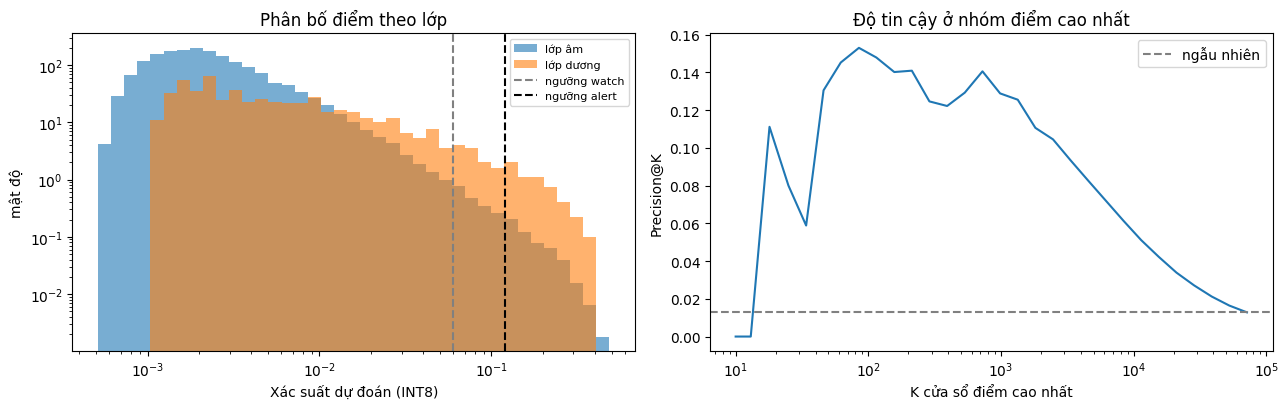

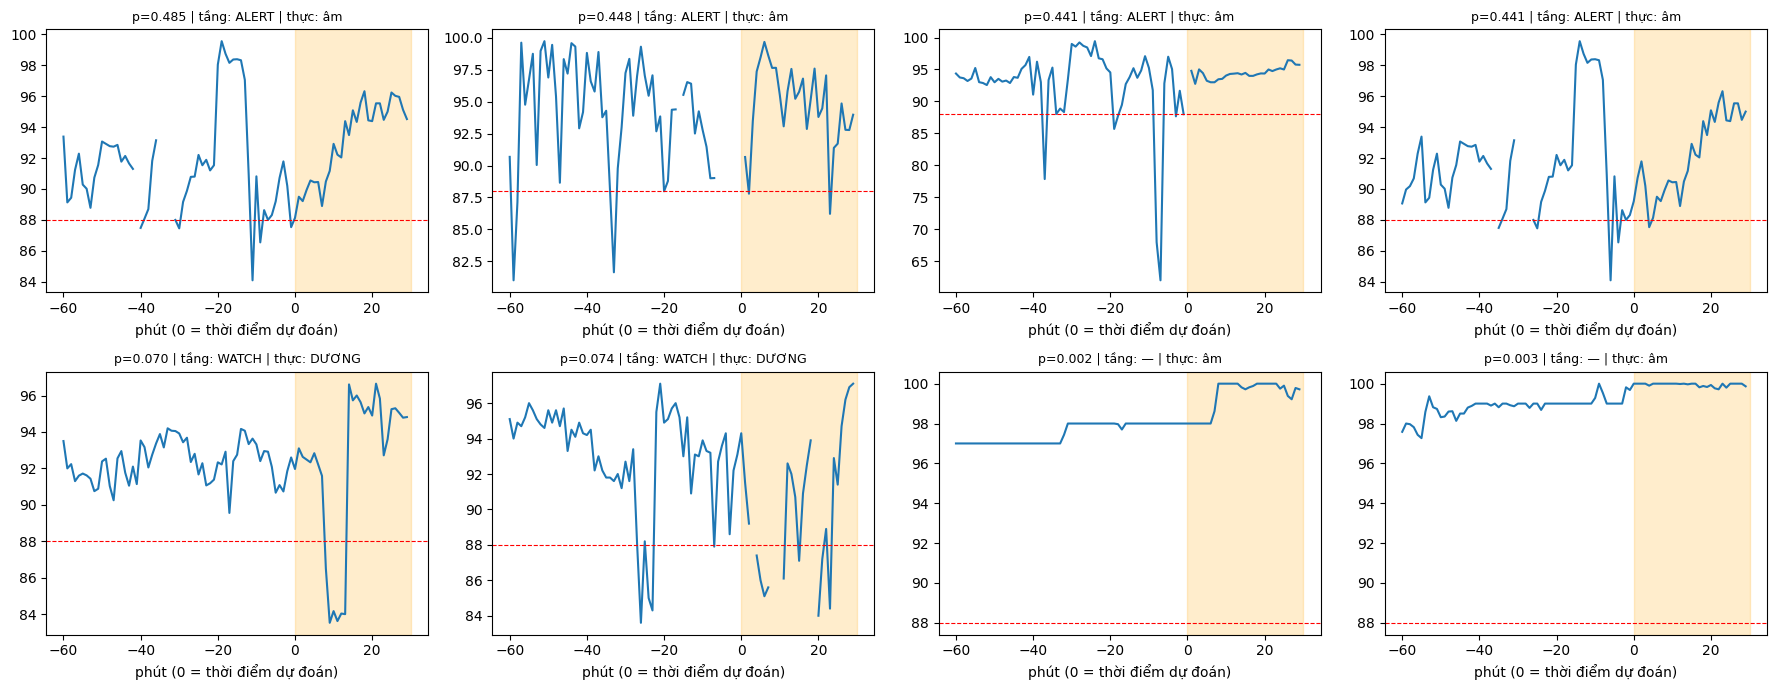

,rec,start,xác_suất_int8,tầng,nhãn_thực
0,p074733-2180-11-23-17-51n,1345,0.4852,ALERT,0
1,p063039-2157-03-29-13-35n,1715,0.4482,ALERT,0
2,p087259-2109-11-28-05-00n,1180,0.4409,ALERT,0
3,p074733-2180-11-23-17-51n,1340,0.4409,ALERT,0
4,p044666-2184-09-16-01-52n,535,0.0703,WATCH,1
5,p021271-2187-08-08-13-57n,4080,0.0742,WATCH,1
6,p004833-2189-06-16-20-45n,1805,0.0016,—,0
7,p046723-2181-12-14-20-43n,2845,0.0032,—,0


In [32]:
p8_test = sig(tflite_logit(XT_te["seq"], XT_te["tab"]))                      # suy luận bằng bản INT8 (đúng thứ chạy trên ESP32)
print(f"AUPRC test | float (seed {DEPLOY}) {average_precision_score(yt, S_test[f'hybrid_s{DEPLOY}']):.4f} | INT8 {average_precision_score(yt, p8_test):.4f}")

# --- kết quả theo lớp tại ngưỡng của từng tầng ---
rows = {}
for t, thr_t in THR_DEV.items():
    pred = p8_test > thr_t
    rows[t] = {"ngưỡng": round(thr_t, 4), "lớp ÂM: số cửa sổ": int((yt == 0).sum()), "lớp ÂM: đúng (specificity)": round(float((~pred)[yt == 0].mean()), 3),
               "lớp DƯƠNG: số cửa sổ": int((yt == 1).sum()), "lớp DƯƠNG: bắt được (recall)": round(float(pred[yt == 1].mean()), 3),
               "precision": round(float(yt[pred].mean()), 3) if pred.any() else np.nan, "accuracy": round(float((pred == yt).mean()), 3)}
display(pd.DataFrame(rows).T)

# --- độ tự tin: trong K cửa sổ có điểm cao nhất, bao nhiêu là dương thật ---
order = np.argsort(-p8_test); base = yt.mean()
display(pd.DataFrame({f"top {k}": dict(precision=round(float(yt[order[:k]].mean()), 3), gấp_mấy_lần_ngẫu_nhiên=round(float(yt[order[:k]].mean() / base), 1)) for k in (20, 50, 100, 500, 2000)}).T)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.geomspace(max(p8_test.min(), 1e-4), p8_test.max(), 40)
ax[0].hist(p8_test[yt == 0], bins=bins, alpha=.6, label="lớp âm", density=True); ax[0].hist(p8_test[yt == 1], bins=bins, alpha=.6, label="lớp dương", density=True)
for t, v in THR_DEV.items(): ax[0].axvline(v, ls="--", c="k" if t == "alert" else "gray", label=f"ngưỡng {t}")
ax[0].set(xscale="log", yscale="log", xlabel="Xác suất dự đoán (INT8)", ylabel="mật độ", title="Phân bố điểm theo lớp"); ax[0].legend(fontsize=8)
ks = np.unique(np.geomspace(10, len(order), 30).astype(int)); ax[1].plot(ks, [yt[order[:k]].mean() for k in ks]); ax[1].axhline(base, ls="--", c="gray", label="ngẫu nhiên")
ax[1].set(xscale="log", xlabel="K cửa sổ điểm cao nhất", ylabel="Precision@K", title="Độ tin cậy ở nhóm điểm cao nhất"); ax[1].legend()
plt.tight_layout(); plt.show()

# --- ví dụ cụ thể: 4 cửa sổ điểm cao nhất, 2 dương ngẫu nhiên, 2 âm ngẫu nhiên ---
rg = np.random.default_rng(3); pick = list(order[:4]) + list(rg.choice(np.where(yt == 1)[0], 2, replace=False)) + list(rg.choice(np.where(yt == 0)[0], 2, replace=False))
fig, ax = plt.subplots(2, 4, figsize=(18, 7)); rec_tab = []
for a, i in zip(ax.ravel(), pick):
    r, s0 = str(MT["rec"][i]), int(MT["start"][i]); sp = pd.read_parquet(f"{CLEAN_DIR}/{r}.parquet", columns=["spo2_mean"])["spo2_mean"].to_numpy()[s0: s0 + 90]
    a.plot(np.arange(-60, -60 + len(sp)), sp); a.axvspan(0, 30, color="orange", alpha=.2); a.axhline(SA.SPO2_THR, ls="--", c="r", lw=.8)
    tier = "ALERT" if p8_test[i] > THR_DEV["alert"] else "WATCH" if p8_test[i] > THR_DEV["watch"] else "—"
    a.set_title(f"p={p8_test[i]:.3f} | tầng: {tier} | thực: {'DƯƠNG' if yt[i] else 'âm'}", fontsize=9); a.set_xlabel("phút (0 = thời điểm dự đoán)")
    rec_tab.append(dict(rec=r, start=s0, xác_suất_int8=round(float(p8_test[i]), 4), tầng=tier, nhãn_thực=int(yt[i])))
plt.tight_layout(); plt.show(); display(pd.DataFrame(rec_tab))

## 9. Tổng kết

### 9.1 Tổng kết tự động

In [33]:
ci = PD.get("lgbm"); H_ = TIER_RES[("alert", "hybrid_ens")][0]; G_ = TIER_RES[("alert", "lgbm")][0] if ("alert", "lgbm") in TIER_RES else None
drop = (average_precision_score(yva, f_val) - average_precision_score(yva, p8_val)) / average_precision_score(yva, f_val)
print("TỔNG KẾT (số liệu tự sinh từ các cell phía trên)\n")
print(f"1. Hybrid ensemble {len(CFG['SEEDS'])} seed: AUPRC test {c_h['summary']['AUPRC']:.3f} (CI95 {c_h['summary']['AUPRC_CI']}), "
      f"gấp {c_h['summary']['lift_vs_random']:.1f} lần mốc ngẫu nhiên; AUROC {c_h['summary']['AUROC']:.3f}.")
if ci is not None:
    v = "tốt hơn" if ci[0] > 0 else "kém hơn" if ci[1] < 0 else "chưa phân biệt được với"
    print(f"2. So với LightGBM: chênh AUPRC CI95 [{ci[0]:.3f}, {ci[1]:.3f}] → hybrid {v} LightGBM về xếp hạng cửa sổ.")
if G_ is not None:
    print(f"3. Tầng Alert (cùng cấu hình): hybrid bắt {H_['caught_useful']:.0%} sự kiện đánh giá được (báo trước ≥ 5 phút) với {H_['FA_per_day']:.2f} báo giả/ngày; "
          f"LightGBM {G_['caught_useful']:.0%} với {G_['FA_per_day']:.2f}/ngày.")
print(f"4. Bản TFLite INT8 (seed {DEPLOY}): {meta['tflite_kb']} KB, AUPRC val giảm {drop:.1%} so với bản float" + (" → cần xem lại lượng tử hóa." if drop > 0.05 else " (trong mức chấp nhận 5%)."))
if ci is None: print("5. Chưa có điểm LightGBM để so sánh; hãy lưu runs/lgbm_val.npy và runs/lgbm_test.npy.")
elif ci[0] > 0: print("5. KẾT LUẬN: hybrid vượt LightGBM có ý nghĩa thống kê → chọn hybrid.")
elif ci[1] < 0: print("5. KẾT LUẬN: hybrid kém LightGBM có ý nghĩa thống kê → chọn LightGBM.")
else: print("5. KẾT LUẬN: hybrid và LightGBM ngang nhau về chất lượng → chọn theo chi phí triển khai và yêu cầu của đề bài (xem mục 9.2).")

TỔNG KẾT (số liệu tự sinh từ các cell phía trên)

1. Hybrid ensemble 3 seed: AUPRC test 0.080 (CI95 0.051-0.111), gấp 6.2 lần mốc ngẫu nhiên; AUROC 0.815.
2. So với LightGBM: chênh AUPRC CI95 [-0.018, 0.010] → hybrid chưa phân biệt được với LightGBM về xếp hạng cửa sổ.
3. Tầng Alert (cùng cấu hình): hybrid bắt 26% sự kiện đánh giá được (báo trước ≥ 5 phút) với 1.28 báo giả/ngày; LightGBM 24% với 1.45/ngày.
4. Bản TFLite INT8 (seed 3): 19.5 KB, AUPRC val giảm 0.3% so với bản float (trong mức chấp nhận 5%).
5. KẾT LUẬN: hybrid và LightGBM ngang nhau về chất lượng → chọn theo chi phí triển khai và yêu cầu của đề bài (xem mục 9.2).


### 9.2 Lựa chọn mô hình và hạn chế

**Các thí nghiệm đã thực hiện** (AUPRC; số liệu ghi từ các lần chạy trước, mốc ngẫu nhiên ≈ 0,012):

| Mô hình | Số seed | Val | Test |
|---|---|---|---|
| Quy tắc (SpO₂ nhỏ nhất 10 phút cuối) | – | 0,047 | 0,050 |
| LightGBM (20 đặc trưng) | 1 | 0,071 | 0,084 |
| 1D-CNN (chỉ chuỗi) | 1 | 0,076 | 0,062 |
| 1D-CNN + augmentation | 3 | 0,063 ± 0,003 | – |
| Hybrid | 3 | 0,067 ± 0,001 | 0,074 ± 0,003 |
| Hybrid ensemble | 3 | 0,069 | 0,076 |

Nhận xét: tín hiệu chủ yếu nằm ở mức SpO₂ gần ngưỡng, nên mô hình chỉ nhận chuỗi thô không vượt các đặc trưng thống kê; hybrid kết hợp cả hai ngang LightGBM nhưng không rõ ràng hơn. Điểm 1D-CNN chỉ chuỗi giảm từ val xuống test, cho thấy việc chọn epoch trên val với một seed có thể lạc quan.

**Tiêu chí chọn model**
1. Chất lượng: hybrid được chọn nếu chênh AUPRC theo cặp so với LightGBM có khoảng tin cậy dương (mục 5.2).
2. Nếu ngang nhau, so chi phí triển khai: LightGBM cần 20 đặc trưng cộng cây; hybrid cần 20 đặc trưng cộng mạng nơ-ron; mạng chỉ chuỗi cần mỗi bước chuẩn hóa nhưng có chất lượng thấp hơn trong các lần thử trên.
3. Nếu đề bài yêu cầu mô hình học sâu thì dùng hybrid và ghi rõ trong báo cáo rằng chất lượng xấp xỉ LightGBM.

**Hạn chế**
- Dữ liệu huấn luyện là bệnh nhân ICU đo bằng máy theo dõi tại giường; MAX30102 khác về cảm biến, hiệu chuẩn và nhiễu chuyển động. Kết quả là bằng chứng khái niệm, chưa khẳng định hiệu quả cho thiết bị đeo.
- Tập test chỉ có khoảng 54 bệnh nhân dương nên khoảng tin cậy rộng; chênh nhỏ giữa các mô hình không đủ để kết luận.
- Tầng dự đoán chỉ bao phủ sự kiện đầu tiên sau một đoạn đầu vào sạch; khoảng một nửa số sự kiện (ở lần chạy LightGBM: 218 trên 439) không nằm trong phạm vi đánh giá và do tầng Critical xử lý.
- Số báo giả/ngày có thể lạc quan do timeline bỏ các cửa sổ ngay sau sự kiện; báo giả tập trung ở một nhóm nhỏ bệnh nhân.
- Bộ nhớ và thời gian suy luận trên ESP32 chưa được đo.